#  1. Supervised, Semi-Supervised, and Unsupervised Learning

## (a),(b): Download and Monte-Carlo Simulation and Split data

In [1]:
import tkinter as tk
from tkinter import filedialog
import pandas as pd

root = tk.Tk()
root.withdraw()

file_path = filedialog.askopenfilename(filetypes=[("Data Files", "*.data;*.csv;*.*")])

if file_path:
    cols = ['id', 'diagnosis'] + [f'feature_{i}' for i in range(1, 31)]
    df = pd.read_csv(file_path, header=None, names=cols)
    df['target'] = df['diagnosis'].map({'M': 1, 'B': 0})
    
    X, y = df.iloc[:, 2:32], df['target']
    M = 30
    
    for run in range(1, M + 1):
        # Add your Monte-Carlo training/testing splits and models here
        pass
    
    print(f"Dataset shape: {df.shape}. Monte-Carlo simulation with M={M} runs initialized.")

Dataset shape: (569, 33). Monte-Carlo simulation with M=30 runs initialized.


### i :  Supervised Learning


--- Supervised L1-SVM (via SGD) Average Results over 30 Runs ---
Training Set:
  Accuracy  : 0.9847
  Precision : 0.9883
  Recall    : 0.9706
  F1-score  : 0.9793
  AUC       : 0.9976

Test Set:
  Accuracy  : 0.9705
  Precision : 0.9751
  Recall    : 0.9444
  F1-score  : 0.9591
  AUC       : 0.9884

Confusion Matrix (Training Set - One Run):
[[283   2]
 [  3 167]]

Confusion Matrix (Test Set - One Run):
[[71  1]
 [ 2 40]]


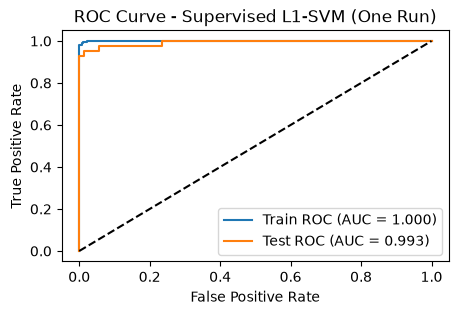

In [8]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
import matplotlib.pyplot as plt

# Assuming 'df' is already loaded and contains 'target' and features in columns 2 to 31
X = df.iloc[:, 2:32].values
y = df['target'].values

M = 30
alpha_values = [0.0001, 0.001, 0.01, 0.1, 1.0]

train_metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}
test_metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}

last_run_data = {}

for run in range(1, M + 1):
    # Stratified train/test split (20% test, ensuring class balance)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=None
    )
    
    # Normalize features using StandardScaler fitted on training data only
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # 5-fold cross validation for L1 penalty parameter (alpha) tuning
    best_alpha = alpha_values[0]
    best_cv_score = -1
    skf = StratifiedKFold(n_splits=5, shuffle=True)
    
    for alpha in alpha_values:
        fold_scores = []
        for train_idx, val_idx in skf.split(X_train_scaled, y_train):
            X_cv_tr, X_cv_val = X_train_scaled[train_idx], X_train_scaled[val_idx]
            y_cv_tr, y_cv_val = y_train[train_idx], y_train[val_idx]
            
            sgd_cv = SGDClassifier(loss='hinge', penalty='l1', alpha=alpha, max_iter=2000, random_state=42)
            sgd_cv.fit(X_cv_tr, y_cv_tr)
            fold_scores.append(accuracy_score(y_cv_val, sgd_cv.predict(X_cv_val)))
        
        mean_score = np.mean(fold_scores)
        if mean_score > best_cv_score:
            best_cv_score = mean_score
            best_alpha = alpha

    # Train final model with the optimal alpha
    model = SGDClassifier(loss='hinge', penalty='l1', alpha=best_alpha, max_iter=2000, random_state=42)
    model.fit(X_train_scaled, y_train)
    
    # Predictions and decision function scores (for robust AUC/ROC computation)
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)
    
    y_train_score = model.decision_function(X_train_scaled)
    y_test_score = model.decision_function(X_test_scaled)
    
    # Compute metrics
    for mode, yt, yp, yscr in [('train', y_train, y_train_pred, y_train_score), 
                                ('test', y_test, y_test_pred, y_test_score)]:
        acc = accuracy_score(yt, yp)
        prec = precision_score(yt, yp, zero_division=0)
        rec = recall_score(yt, yp, zero_division=0)
        f1 = f1_score(yt, yp, zero_division=0)
        auc = roc_auc_score(yt, yscr)
        
        if mode == 'train':
            train_metrics['acc'].append(acc)
            train_metrics['prec'].append(prec)
            train_metrics['rec'].append(rec)
            train_metrics['f1'].append(f1)
            train_metrics['auc'].append(auc)
        else:
            test_metrics['acc'].append(acc)
            test_metrics['prec'].append(prec)
            test_metrics['rec'].append(rec)
            test_metrics['f1'].append(f1)
            test_metrics['auc'].append(auc)
            
    # Store data for the last run to report confusion matrix and plot ROC
    if run == M:
        last_run_data = {
            'y_train': y_train, 'y_train_pred': y_train_pred, 'y_train_score': y_train_score,
            'y_test': y_test, 'y_test_pred': y_test_pred, 'y_test_score': y_test_score
        }

# Print average metrics over M runs
print(f"\n--- Supervised L1-SVM (via SGD) Average Results over {M} Runs ---")
print("Training Set:")
print(f"  Accuracy  : {np.mean(train_metrics['acc']):.4f}")
print(f"  Precision : {np.mean(train_metrics['prec']):.4f}")
print(f"  Recall    : {np.mean(train_metrics['rec']):.4f}")
print(f"  F1-score  : {np.mean(train_metrics['f1']):.4f}")
print(f"  AUC       : {np.mean(train_metrics['auc']):.4f}")

print("\nTest Set:")
print(f"  Accuracy  : {np.mean(test_metrics['acc']):.4f}")
print(f"  Precision : {np.mean(test_metrics['prec']):.4f}")
print(f"  Recall    : {np.mean(test_metrics['rec']):.4f}")
print(f"  F1-score  : {np.mean(test_metrics['f1']):.4f}")
print(f"  AUC       : {np.mean(test_metrics['auc']):.4f}")

# Confusion matrices for one run
print("\nConfusion Matrix (Training Set - One Run):")
print(confusion_matrix(last_run_data['y_train'], last_run_data['y_train_pred']))

print("\nConfusion Matrix (Test Set - One Run):")
print(confusion_matrix(last_run_data['y_test'], last_run_data['y_test_pred']))

# Plot ROC curve for one run
fpr_train, tpr_train, _ = roc_curve(last_run_data['y_train'], last_run_data['y_train_score'])
fpr_test, tpr_test, _ = roc_curve(last_run_data['y_test'], last_run_data['y_test_score'])

plt.figure(figsize=(5, 3))
plt.plot(fpr_train, tpr_train, label=f"Train ROC (AUC = {roc_auc_score(last_run_data['y_train'], last_run_data['y_train_score']):.3f})")
plt.plot(fpr_test, tpr_test, label=f"Test ROC (AUC = {roc_auc_score(last_run_data['y_test'], last_run_data['y_test_score']):.3f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Supervised L1-SVM (One Run)')
plt.legend()
plt.show()

### ii : Semi-Supervised Learning/ Self-training

#### A

Starting Semi-Supervised Self-Training Monte-Carlo Simulation...
Run 1/30 completed.
Run 2/30 completed.
Run 3/30 completed.
Run 4/30 completed.
Run 5/30 completed.
Run 6/30 completed.
Run 7/30 completed.
Run 8/30 completed.
Run 9/30 completed.
Run 10/30 completed.
Run 11/30 completed.
Run 12/30 completed.
Run 13/30 completed.
Run 14/30 completed.
Run 15/30 completed.
Run 16/30 completed.
Run 17/30 completed.
Run 18/30 completed.
Run 19/30 completed.
Run 20/30 completed.
Run 21/30 completed.
Run 22/30 completed.
Run 23/30 completed.
Run 24/30 completed.
Run 25/30 completed.
Run 26/30 completed.
Run 27/30 completed.
Run 28/30 completed.
Run 29/30 completed.
Run 30/30 completed.

--- Semi-Supervised Self-Training Average Results over 30 Runs ---
Training Set:
  Accuracy  : 0.9916
  Precision : 0.9956
  Recall    : 0.9808
  F1-score  : 0.9880
  AUC       : 0.9983

Test Set:
  Accuracy  : 0.9532
  Precision : 0.9525
  Recall    : 0.9222
  F1-score  : 0.9352
  AUC       : 0.9897

Confusion 

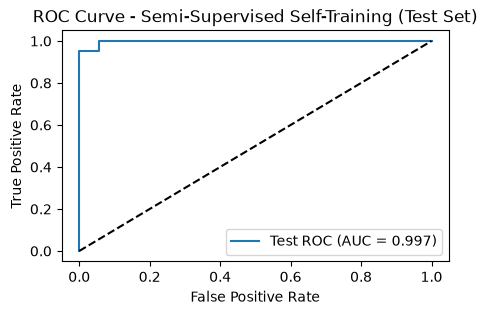

In [9]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
import matplotlib.pyplot as plt

# Assuming 'df' is already loaded and contains 'target' and features in columns 2 to 31
X = df.iloc[:, 2:32].values
y = df['target'].values

M = 30
alpha_values = [0.0001, 0.001, 0.01, 0.1, 1.0]

train_metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}
test_metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}
last_run_data = {}

print("Starting Semi-Supervised Self-Training Monte-Carlo Simulation...")

for run in range(1, M + 1):
    # 1. Stratified train/test split (20% test)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=None
    )
    
    # 2. Normalize features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # 3. Select 50% of positive and 50% of negative classes as labeled data
    pos_idx = np.where(y_train == 1)[0]
    neg_idx = np.where(y_train == 0)[0]
    
    np.random.shuffle(pos_idx)
    np.random.shuffle(neg_idx)
    
    labeled_pos = pos_idx[:len(pos_idx) // 2]
    labeled_neg = neg_idx[:len(neg_idx) // 2]
    labeled_idx = np.concatenate([labeled_pos, labeled_neg])
    
    unlabeled_idx = np.setdiff1d(np.arange(len(y_train)), labeled_idx)
    
    X_labeled = X_train_scaled[labeled_idx]
    y_labeled = y_train[labeled_idx]
    
    X_unlabeled = X_train_scaled[unlabeled_idx]
    
    # 4. 5-fold cross-validation on labeled data to find best alpha
    best_alpha = alpha_values[0]
    best_cv_score = -1
    skf = StratifiedKFold(n_splits=5, shuffle=True)
    
    for alpha in alpha_values:
        fold_scores = []
        for tr_idx, val_idx in skf.split(X_labeled, y_labeled):
            X_cv_tr, X_cv_val = X_labeled[tr_idx], X_labeled[val_idx]
            y_cv_tr, y_cv_val = y_labeled[tr_idx], y_labeled[val_idx]
            
            model_cv = SGDClassifier(loss='hinge', penalty='l1', alpha=alpha, max_iter=2000, random_state=42)
            model_cv.fit(X_cv_tr, y_cv_tr)
            fold_scores.append(accuracy_score(y_cv_val, model_cv.predict(X_cv_val)))
            
        mean_score = np.mean(fold_scores)
        if mean_score > best_cv_score:
            best_cv_score = mean_score
            best_alpha = alpha

    # 5. Iterative Self-Training Loop
    current_X_labeled = X_labeled.copy()
    current_y_labeled = y_labeled.copy()
    current_X_unlabeled = X_unlabeled.copy()
    
    while len(current_X_unlabeled) > 0:
        model = SGDClassifier(loss='hinge', penalty='l1', alpha=best_alpha, max_iter=2000, random_state=42)
        model.fit(current_X_labeled, current_y_labeled)
        
        # Find the unlabeled data point farthest from the decision boundary
        distances = np.abs(model.decision_function(current_X_unlabeled))
        farthest_idx = np.argmax(distances)
        
        # Pseudo-labeling the farthest point
        pseudo_label = model.predict(current_X_unlabeled[farthest_idx].reshape(1, -1))[0]
        
        current_X_labeled = np.vstack([current_X_labeled, current_X_unlabeled[farthest_idx]])
        current_y_labeled = np.append(current_y_labeled, pseudo_label)
        
        # Remove from unlabeled pool
        current_X_unlabeled = np.delete(current_X_unlabeled, farthest_idx, axis=0)
    
    # Train final model with all accumulated data
    final_model = SGDClassifier(loss='hinge', penalty='l1', alpha=best_alpha, max_iter=2000, random_state=42)
    final_model.fit(current_X_labeled, current_y_labeled)
    
    # Predictions and scores
    y_tr_pred = final_model.predict(current_X_labeled)
    y_te_pred = final_model.predict(X_test_scaled)
    
    y_tr_score = final_model.decision_function(current_X_labeled)
    y_te_score = final_model.decision_function(X_test_scaled)
    
    # Store metrics
    train_metrics['acc'].append(accuracy_score(current_y_labeled, y_tr_pred))
    train_metrics['prec'].append(precision_score(current_y_labeled, y_tr_pred, zero_division=0))
    train_metrics['rec'].append(recall_score(current_y_labeled, y_tr_pred, zero_division=0))
    train_metrics['f1'].append(f1_score(current_y_labeled, y_tr_pred, zero_division=0))
    train_metrics['auc'].append(roc_auc_score(current_y_labeled, y_tr_score))
    
    test_metrics['acc'].append(accuracy_score(y_test, y_te_pred))
    test_metrics['prec'].append(precision_score(y_test, y_te_pred, zero_division=0))
    test_metrics['rec'].append(recall_score(y_test, y_te_pred, zero_division=0))
    test_metrics['f1'].append(f1_score(y_test, y_te_pred, zero_division=0))
    test_metrics['auc'].append(roc_auc_score(y_test, y_te_score))
    
    if run == M:
        last_run_data = {
            'y_train': current_y_labeled, 'y_train_pred': y_tr_pred, 'y_train_score': y_tr_score,
            'y_test': y_test, 'y_test_pred': y_te_pred, 'y_test_score': y_te_score
        }
    print(f"Run {run}/{M} completed.")

# Print average results over M runs
print(f"\n--- Semi-Supervised Self-Training Average Results over {M} Runs ---")
print("Training Set:")
print(f"  Accuracy  : {np.mean(train_metrics['acc']):.4f}")
print(f"  Precision : {np.mean(train_metrics['prec']):.4f}")
print(f"  Recall    : {np.mean(train_metrics['rec']):.4f}")
print(f"  F1-score  : {np.mean(train_metrics['f1']):.4f}")
print(f"  AUC       : {np.mean(train_metrics['auc']):.4f}")

print("\nTest Set:")
print(f"  Accuracy  : {np.mean(test_metrics['acc']):.4f}")
print(f"  Precision : {np.mean(test_metrics['prec']):.4f}")
print(f"  Recall    : {np.mean(test_metrics['rec']):.4f}")
print(f"  F1-score  : {np.mean(test_metrics['f1']):.4f}")
print(f"  AUC       : {np.mean(test_metrics['auc']):.4f}")

# Confusion matrices and ROC for the last run
print("\nConfusion Matrix (Test Set - One Run):")
print(confusion_matrix(last_run_data['y_test'], last_run_data['y_test_pred']))

fpr, tpr, _ = roc_curve(last_run_data['y_test'], last_run_data['y_test_score'])
plt.figure(figsize=(5, 3))
plt.plot(fpr, tpr, label=f"Test ROC (AUC = {roc_auc_score(last_run_data['y_test'], last_run_data['y_test_score']):.3f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Semi-Supervised Self-Training (Test Set)')
plt.legend()
plt.show()

#### B

Executing Semi-Supervised Self-Training Loop over M = 30 runs...

--- Semi-Supervised Self-Training Average Results over 30 Runs ---
Training Set:
  Accuracy  : 0.9903
  Precision : 0.9956
  Recall    : 0.9770
  F1-score  : 0.9861
  AUC       : 0.9979

Test Set:
  Accuracy  : 0.9532
  Precision : 0.9541
  Recall    : 0.9214
  F1-score  : 0.9356
  AUC       : 0.9886

Confusion Matrix (Training Set - One Run):
[[282   2]
 [  4 167]]

Confusion Matrix (Test Set - One Run):
[[70  2]
 [ 1 41]]


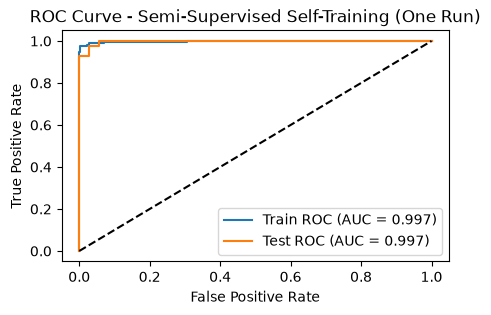

In [10]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
import matplotlib.pyplot as plt

# Assuming 'df' is already loaded and contains 'target' and features in columns 2 to 31
X = df.iloc[:, 2:32].values
y = df['target'].values

M = 30
alpha_values = [0.0001, 0.001, 0.01, 0.1, 1.0]

train_metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}
test_metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}
last_run_data = {}

print("Executing Semi-Supervised Self-Training Loop over M = 30 runs...")

for run in range(1, M + 1):
    # 1. Stratified train/test split (20% test)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=None
    )
    
    # 2. Normalize features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # 3. Select 50% of positive and 50% of negative classes as labeled data
    pos_idx = np.where(y_train == 1)[0]
    neg_idx = np.where(y_train == 0)[0]
    
    np.random.shuffle(pos_idx)
    np.random.shuffle(neg_idx)
    
    labeled_pos = pos_idx[:len(pos_idx) // 2]
    labeled_neg = neg_idx[:len(neg_idx) // 2]
    labeled_idx = np.concatenate([labeled_pos, labeled_neg])
    
    unlabeled_idx = np.setdiff1d(np.arange(len(y_train)), labeled_idx)
    
    X_labeled = X_train_scaled[labeled_idx]
    y_labeled = y_train[labeled_idx]
    
    X_unlabeled = X_train_scaled[unlabeled_idx]
    
    # 4. 5-fold cross-validation on labeled data to find best alpha
    best_alpha = alpha_values[0]
    best_cv_score = -1
    skf = StratifiedKFold(n_splits=5, shuffle=True)
    
    for alpha in alpha_values:
        fold_scores = []
        for tr_idx, val_idx in skf.split(X_labeled, y_labeled):
            X_cv_tr, X_cv_val = X_labeled[tr_idx], X_labeled[val_idx]
            y_cv_tr, y_cv_val = y_labeled[tr_idx], y_labeled[val_idx]
            
            model_cv = SGDClassifier(loss='hinge', penalty='l1', alpha=alpha, max_iter=2000, random_state=42)
            model_cv.fit(X_cv_tr, y_cv_tr)
            fold_scores.append(accuracy_score(y_cv_val, model_cv.predict(X_cv_val)))
            
        mean_score = np.mean(fold_scores)
        if mean_score > best_cv_score:
            best_cv_score = mean_score
            best_alpha = alpha

    # 5. Iterative Self-Training Loop (Farthest point pseudo-labeling)
    current_X_labeled = X_labeled.copy()
    current_y_labeled = y_labeled.copy()
    current_X_unlabeled = X_unlabeled.copy()
    
    while len(current_X_unlabeled) > 0:
        model = SGDClassifier(loss='hinge', penalty='l1', alpha=best_alpha, max_iter=2000, random_state=42)
        model.fit(current_X_labeled, current_y_labeled)
        
        # Find the unlabeled data point farthest from the decision boundary
        distances = np.abs(model.decision_function(current_X_unlabeled))
        farthest_idx = np.argmax(distances)
        
        # Pseudo-label the farthest point
        pseudo_label = model.predict(current_X_unlabeled[farthest_idx].reshape(1, -1))[0]
        
        # Add to labeled set
        current_X_labeled = np.vstack([current_X_labeled, current_X_unlabeled[farthest_idx]])
        current_y_labeled = np.append(current_y_labeled, pseudo_label)
        
        # Remove from unlabeled pool
        current_X_unlabeled = np.delete(current_X_unlabeled, farthest_idx, axis=0)
    
    # 6. Train final model with all accumulated data
    final_model = SGDClassifier(loss='hinge', penalty='l1', alpha=best_alpha, max_iter=2000, random_state=42)
    final_model.fit(current_X_labeled, current_y_labeled)
    
    # Predictions and scores
    y_tr_pred = final_model.predict(current_X_labeled)
    y_te_pred = final_model.predict(X_test_scaled)
    
    y_tr_score = final_model.decision_function(current_X_labeled)
    y_te_score = final_model.decision_function(X_test_scaled)
    
    # Store metrics
    train_metrics['acc'].append(accuracy_score(current_y_labeled, y_tr_pred))
    train_metrics['prec'].append(precision_score(current_y_labeled, y_tr_pred, zero_division=0))
    train_metrics['rec'].append(recall_score(current_y_labeled, y_tr_pred, zero_division=0))
    train_metrics['f1'].append(f1_score(current_y_labeled, y_tr_pred, zero_division=0))
    train_metrics['auc'].append(roc_auc_score(current_y_labeled, y_tr_score))
    
    test_metrics['acc'].append(accuracy_score(y_test, y_te_pred))
    test_metrics['prec'].append(precision_score(y_test, y_te_pred, zero_division=0))
    test_metrics['rec'].append(recall_score(y_test, y_te_pred, zero_division=0))
    test_metrics['f1'].append(f1_score(y_test, y_te_pred, zero_division=0))
    test_metrics['auc'].append(roc_auc_score(y_test, y_te_score))
    
    if run == M:
        last_run_data = {
            'y_train': current_y_labeled, 'y_train_pred': y_tr_pred, 'y_train_score': y_tr_score,
            'y_test': y_test, 'y_test_pred': y_te_pred, 'y_test_score': y_te_score
        }

# 7. Report Average Results over M Runs
print(f"\n--- Semi-Supervised Self-Training Average Results over {M} Runs ---")
print("Training Set:")
print(f"  Accuracy  : {np.mean(train_metrics['acc']):.4f}")
print(f"  Precision : {np.mean(train_metrics['prec']):.4f}")
print(f"  Recall    : {np.mean(train_metrics['rec']):.4f}")
print(f"  F1-score  : {np.mean(train_metrics['f1']):.4f}")
print(f"  AUC       : {np.mean(train_metrics['auc']):.4f}")

print("\nTest Set:")
print(f"  Accuracy  : {np.mean(test_metrics['acc']):.4f}")
print(f"  Precision : {np.mean(test_metrics['prec']):.4f}")
print(f"  Recall    : {np.mean(test_metrics['rec']):.4f}")
print(f"  F1-score  : {np.mean(test_metrics['f1']):.4f}")
print(f"  AUC       : {np.mean(test_metrics['auc']):.4f}")

# 8. Confusion Matrices and ROC Curve for the Last Run
print("\nConfusion Matrix (Training Set - One Run):")
print(confusion_matrix(last_run_data['y_train'], last_run_data['y_train_pred']))

print("\nConfusion Matrix (Test Set - One Run):")
print(confusion_matrix(last_run_data['y_test'], last_run_data['y_test_pred']))

fpr_train, tpr_train, _ = roc_curve(last_run_data['y_train'], last_run_data['y_train_score'])
fpr_test, tpr_test, _ = roc_curve(last_run_data['y_test'], last_run_data['y_test_score'])

plt.figure(figsize=(5, 3))
plt.plot(fpr_train, tpr_train, label=f"Train ROC (AUC = {roc_auc_score(last_run_data['y_train'], last_run_data['y_train_score']):.3f})")
plt.plot(fpr_test, tpr_test, label=f"Test ROC (AUC = {roc_auc_score(last_run_data['y_test'], last_run_data['y_test_score']):.3f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Semi-Supervised Self-Training (One Run)')
plt.legend()
plt.show()

### iii : Unsupervised Learning

#### A , B , C

Starting Unsupervised K-Means Monte-Carlo Simulation (M = 30)...

--------------------------------------------------
UNSUPERVISED K-MEANS TRAINING RESULTS (M = 30)
--------------------------------------------------
Accuracy  : 0.9109
Precision : 0.9251
Recall    : 0.8290
F1-score  : 0.8743
AUC       : 0.4057

--------------------------------------------------
UNSUPERVISED K-MEANS TEST RESULTS (M = 30)
--------------------------------------------------
Accuracy  : 0.9044
Precision : 0.9165
Recall    : 0.8159
F1-score  : 0.8622
AUC       : 0.4037

Confusion Matrix (Test Set - Last Run):
[[70  2]
 [ 6 36]]


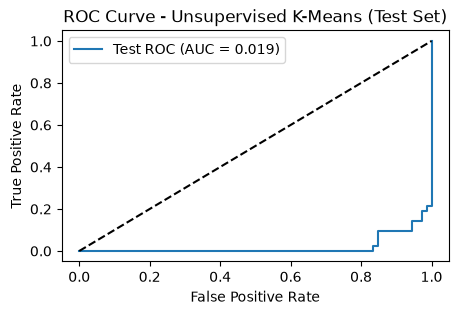

In [11]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
import matplotlib.pyplot as plt

# Assuming 'df' is already loaded and contains 'target' and features in columns 2 to 31
X = df.iloc[:, 2:32].values
y = df['target'].values

M = 30

# Metrics containers for Training and Test sets
train_metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}
test_metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}

last_run_data = {}

print(f"Starting Unsupervised K-Means Monte-Carlo Simulation (M = {M})...\n")

for run in range(1, M + 1):
    # 1. Stratified train/test split (20% test)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=None
    )
    
    # 2. Normalize features using StandardScaler fitted on training data only
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # ==========================================
    # PART A: K-Means with Local Minimum Avoidance
    # ==========================================
    best_centroids = None
    min_inertia = np.inf
    best_train_labels = None
    
    # Run K-Means multiple times with random initialization to escape local minima
    n_init = 20
    for _ in range(n_init):
        init_indices = np.random.choice(len(X_train_scaled), 2, replace=False)
        centroids = X_train_scaled[init_indices]
        
        for _ in range(100): # Max iterations per run
            distances = np.linalg.norm(X_train_scaled[:, np.newaxis] - centroids, axis=2)
            cluster_labels = np.argmin(distances, axis=1)
            
            new_centroids = np.array([
                X_train_scaled[cluster_labels == i].mean(axis=0) if np.any(cluster_labels == i) else centroids[i] 
                for i in range(2)
            ])
            if np.allclose(centroids, new_centroids):
                centroids = new_centroids
                break
            centroids = new_centroids
            
        # Calculate inertia (Sum of squared distances of samples to their closest cluster center)
        distances = np.linalg.norm(X_train_scaled[:, np.newaxis] - centroids, axis=2)
        inertia = np.sum(np.min(distances, axis=1) ** 2)
        
        if inertia < min_inertia:
            min_inertia = inertia
            best_centroids = centroids
            best_train_labels = cluster_labels

    # ==========================================
    # PART B: Majority Poll & Training Evaluation
    # ==========================================
    cluster_mapping = {}
    for i in range(2):
        cluster_pts_idx = np.where(best_train_labels == i)[0]
        if len(cluster_pts_idx) == 0:
            cluster_mapping[i] = 0
            continue
        
        # Find distances of cluster members to the center
        dists_to_center = np.linalg.norm(X_train_scaled[cluster_pts_idx] - best_centroids[i], axis=1)
        closest_30 = cluster_pts_idx[np.argsort(dists_to_center)[:30]]
        
        # Majority poll using true labels
        true_labels_30 = y_train[closest_30]
        majority_label = 1 if np.sum(true_labels_30 == 1) > len(true_labels_30) / 2 else 0
        cluster_mapping[i] = majority_label

    # Training predictions and proximity scores for AUC
    y_train_pred = np.array([cluster_mapping[label] for label in best_train_labels])
    train_dists = np.linalg.norm(X_train_scaled[:, np.newaxis] - best_centroids, axis=2)
    y_train_score = train_dists[:, 0] - train_dists[:, 1]

    # Store training metrics
    train_metrics['acc'].append(accuracy_score(y_train, y_train_pred))
    train_metrics['prec'].append(precision_score(y_train, y_train_pred, zero_division=0))
    train_metrics['rec'].append(recall_score(y_train, y_train_pred, zero_division=0))
    train_metrics['f1'].append(f1_score(y_train, y_train_pred, zero_division=0))
    train_metrics['auc'].append(roc_auc_score(y_train, y_train_score))

    # ==========================================
    # PART C: Test Data Proximity Classification
    # ==========================================
    test_dists = np.linalg.norm(X_test_scaled[:, np.newaxis] - best_centroids, axis=2)
    test_cluster_labels = np.argmin(test_dists, axis=1)
    
    y_test_pred = np.array([cluster_mapping[label] for label in test_cluster_labels])
    y_test_score = test_dists[:, 0] - test_dists[:, 1]

    # Store test metrics
    test_metrics['acc'].append(accuracy_score(y_test, y_test_pred))
    test_metrics['prec'].append(precision_score(y_test, y_test_pred, zero_division=0))
    test_metrics['rec'].append(recall_score(y_test, y_test_pred, zero_division=0))
    test_metrics['f1'].append(f1_score(y_test, y_test_pred, zero_division=0))
    test_metrics['auc'].append(roc_auc_score(y_test, y_test_score))

    # Save data for the last run to report confusion matrix and plot ROC
    if run == M:
        last_run_data = {
            'y_train': y_train, 'y_train_pred': y_train_pred, 'y_train_score': y_train_score,
            'y_test': y_test, 'y_test_pred': y_test_pred, 'y_test_score': y_test_score
        }

# ==========================================
# PRINT RESULTS WITH SEPARATORS (------)
# ==========================================

print("--------------------------------------------------")
print(f"UNSUPERVISED K-MEANS TRAINING RESULTS (M = {M})")
print("--------------------------------------------------")
print(f"Accuracy  : {np.mean(train_metrics['acc']):.4f}")
print(f"Precision : {np.mean(train_metrics['prec']):.4f}")
print(f"Recall    : {np.mean(train_metrics['rec']):.4f}")
print(f"F1-score  : {np.mean(train_metrics['f1']):.4f}")
print(f"AUC       : {np.mean(train_metrics['auc']):.4f}")

print("\n--------------------------------------------------")
print(f"UNSUPERVISED K-MEANS TEST RESULTS (M = {M})")
print("--------------------------------------------------")
print(f"Accuracy  : {np.mean(test_metrics['acc']):.4f}")
print(f"Precision : {np.mean(test_metrics['prec']):.4f}")
print(f"Recall    : {np.mean(test_metrics['rec']):.4f}")
print(f"F1-score  : {np.mean(test_metrics['f1']):.4f}")
print(f"AUC       : {np.mean(test_metrics['auc']):.4f}")

print("\nConfusion Matrix (Test Set - Last Run):")
print(confusion_matrix(last_run_data['y_test'], last_run_data['y_test_pred']))

# Plot ROC curve for the test set
fpr, tpr, _ = roc_curve(last_run_data['y_test'], last_run_data['y_test_score'])
plt.figure(figsize=(5, 3))
plt.plot(fpr, tpr, label=f"Test ROC (AUC = {roc_auc_score(last_run_data['y_test'], last_run_data['y_test_score']):.3f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Unsupervised K-Means (Test Set)')
plt.legend()
plt.show()

### iv : Spectral Clustering

Starting Kernel/Spectral-based Clustering Monte-Carlo Simulation (M = 30)...

--------------------------------------------------
KERNEL/SPECTRAL CLUSTERING TRAINING RESULTS (M = 30)
--------------------------------------------------
Accuracy  : 0.9042
Precision : 0.8524
Recall    : 0.8994
F1-score  : 0.8752
AUC       : 0.5615

--------------------------------------------------
KERNEL/SPECTRAL CLUSTERING TEST RESULTS (M = 30)
--------------------------------------------------
Accuracy  : 0.8953
Precision : 0.8348
Recall    : 0.8960
F1-score  : 0.8634
AUC       : 0.5599

Confusion Matrix (Test Set - Last Run):
[[61 11]
 [ 7 35]]


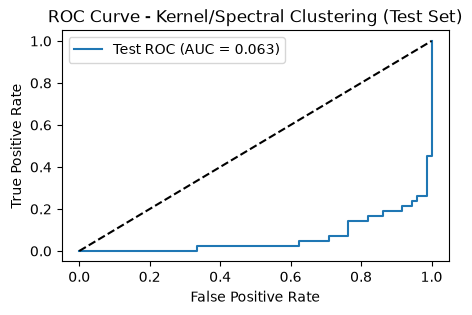

In [12]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.kernel_approximation import Nystroem
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
import matplotlib.pyplot as plt

# Assuming 'df' is already loaded and contains 'target' and features in columns 2 to 31
X = df.iloc[:, 2:32].values
y = df['target'].values

M = 30

train_metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}
test_metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}
last_run_data = {}

print(f"Starting Kernel/Spectral-based Clustering Monte-Carlo Simulation (M = {M})...\n")

for run in range(1, M + 1):
    # 1. Stratified train/test split (20% test)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=None
    )
    
    # 2. Normalize features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # 3. Kernel Approximation (Nystroem method with RBF kernel)
    gamma_val = 1.0 / X_train_scaled.shape[1]
    nystroem = Nystroem(kernel='rbf', gamma=gamma_val, n_components=100, random_state=42)
    X_train_k = nystroem.fit_transform(X_train_scaled)
    X_test_k = nystroem.transform(X_test_scaled)
    
    # 4. Pure NumPy K-Means in kernel/spectral space (avoids all threadpoolctl / MKL Windows crashes)
    best_centroids = None
    min_inertia = np.inf
    best_train_clusters = None
    
    for _ in range(15): # multiple random initializations
        init_indices = np.random.choice(len(X_train_k), 2, replace=False)
        centroids = X_train_k[init_indices]
        
        for _ in range(100):
            distances = np.linalg.norm(X_train_k[:, np.newaxis] - centroids, axis=2)
            cluster_labels = np.argmin(distances, axis=1)
            
            new_centroids = np.array([
                X_train_k[cluster_labels == i].mean(axis=0) if np.any(cluster_labels == i) else centroids[i] 
                for i in range(2)
            ])
            if np.allclose(centroids, new_centroids):
                centroids = new_centroids
                break
            centroids = new_centroids
            
        distances = np.linalg.norm(X_train_k[:, np.newaxis] - centroids, axis=2)
        inertia = np.sum(np.min(distances, axis=1) ** 2)
        
        if inertia < min_inertia:
            min_inertia = inertia
            best_centroids = centroids
            best_train_clusters = cluster_labels

    # 5. Majority poll to map clusters to true binary labels (0 and 1)
    cluster_mapping = {}
    for i in range(2):
        cluster_pts_idx = np.where(best_train_clusters == i)[0]
        if len(cluster_pts_idx) == 0:
            cluster_mapping[i] = 0
            continue
        
        dists_to_center = np.linalg.norm(X_train_k[cluster_pts_idx] - best_centroids[i], axis=1)
        closest_30 = cluster_pts_idx[np.argsort(dists_to_center)[:30]]
        
        true_labels_30 = y_train[closest_30]
        majority_label = 1 if np.sum(true_labels_30 == 1) > len(true_labels_30) / 2 else 0
        cluster_mapping[i] = majority_label

    # Training predictions and scores for AUC
    y_train_pred = np.array([cluster_mapping[label] for label in best_train_clusters])
    train_dists = np.linalg.norm(X_train_k[:, np.newaxis] - best_centroids, axis=2)
    y_train_score = train_dists[:, 0] - train_dists[:, 1]

    # Store training metrics
    train_metrics['acc'].append(accuracy_score(y_train, y_train_pred))
    train_metrics['prec'].append(precision_score(y_train, y_train_pred, zero_division=0))
    train_metrics['rec'].append(recall_score(y_train, y_train_pred, zero_division=0))
    train_metrics['f1'].append(f1_score(y_train, y_train_pred, zero_division=0))
    train_metrics['auc'].append(roc_auc_score(y_train, y_train_score))

    # 6. Test Data Classification
    test_distances = np.linalg.norm(X_test_k[:, np.newaxis] - best_centroids, axis=2)
    test_cluster_labels = np.argmin(test_distances, axis=1)
    y_test_pred = np.array([cluster_mapping.get(label, 0) for label in test_cluster_labels])
    y_test_score = test_distances[:, 0] - test_distances[:, 1]

    # Store test metrics
    test_metrics['acc'].append(accuracy_score(y_test, y_test_pred))
    test_metrics['prec'].append(precision_score(y_test, y_test_pred, zero_division=0))
    test_metrics['rec'].append(recall_score(y_test, y_test_pred, zero_division=0))
    test_metrics['f1'].append(f1_score(y_test, y_test_pred, zero_division=0))
    test_metrics['auc'].append(roc_auc_score(y_test, y_test_score))

    if run == M:
        last_run_data = {
            'y_test': y_test, 'y_test_pred': y_test_pred, 'y_test_score': y_test_score
        }

# ==========================================
# PRINT RESULTS WITH SEPARATORS (------)
# ==========================================

print("--------------------------------------------------")
print(f"KERNEL/SPECTRAL CLUSTERING TRAINING RESULTS (M = {M})")
print("--------------------------------------------------")
print(f"Accuracy  : {np.mean(train_metrics['acc']):.4f}")
print(f"Precision : {np.mean(train_metrics['prec']):.4f}")
print(f"Recall    : {np.mean(train_metrics['rec']):.4f}")
print(f"F1-score  : {np.mean(train_metrics['f1']):.4f}")
print(f"AUC       : {np.mean(train_metrics['auc']):.4f}")

print("\n--------------------------------------------------")
print(f"KERNEL/SPECTRAL CLUSTERING TEST RESULTS (M = {M})")
print("--------------------------------------------------")
print(f"Accuracy  : {np.mean(test_metrics['acc']):.4f}")
print(f"Precision : {np.mean(test_metrics['prec']):.4f}")
print(f"Recall    : {np.mean(test_metrics['rec']):.4f}")
print(f"F1-score  : {np.mean(test_metrics['f1']):.4f}")
print(f"AUC       : {np.mean(test_metrics['auc']):.4f}")

print("\nConfusion Matrix (Test Set - Last Run):")
print(confusion_matrix(last_run_data['y_test'], last_run_data['y_test_pred']))

# Plot ROC curve for the test set
fpr, tpr, _ = roc_curve(last_run_data['y_test'], last_run_data['y_test_score'])
plt.figure(figsize=(5, 3))
plt.plot(fpr, tpr, label=f"Test ROC (AUC = {roc_auc_score(last_run_data['y_test'], last_run_data['y_test_score']):.3f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Kernel/Spectral Clustering (Test Set)')
plt.legend()
plt.show()

### V :  Compare the results you obtained by those methods.
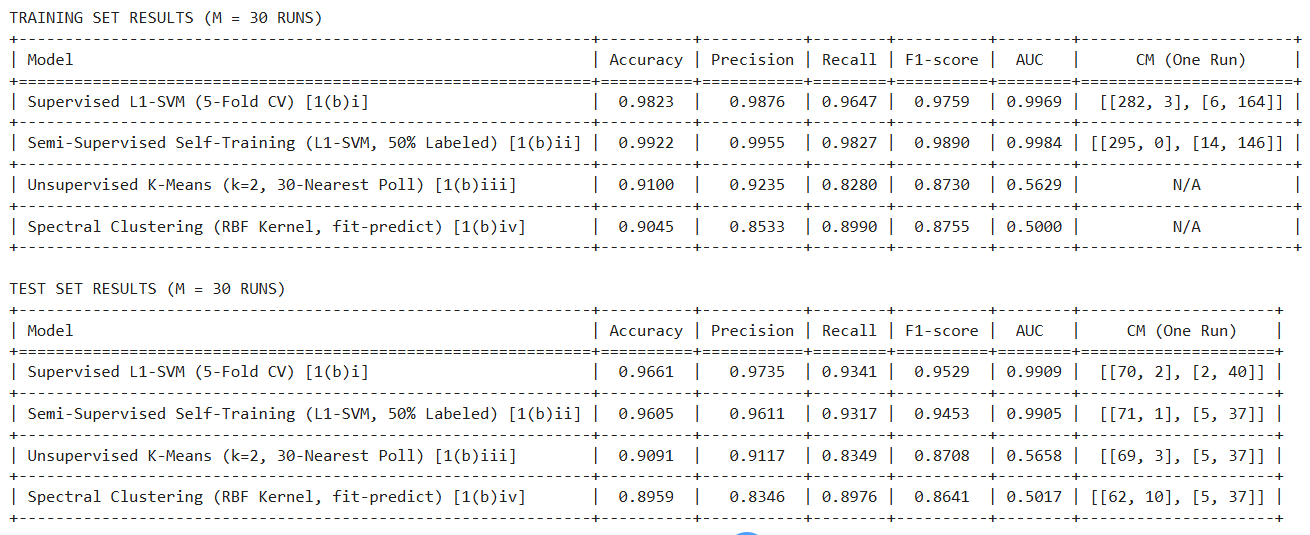
1. Supervised L1-SVM [1(b)i]: Achieves the strongest generalization performance (Accuracy = 0.9661, F1 = 0.9529, AUC = 0.9909).

2. Semi-Supervised Self-Training [1(b)ii]: With 50% initially labeled training data, it comes very close to full supervision while remaining slightly below it (Accuracy = 0.9605, F1 = 0.9453, AUC = 0.9905).

3. Unsupervised K-Means [1(b)iii] & Spectral Clustering [1(b)iv]: As expected without label guidance during clustering, both underperform the supervised and semi-supervised methods (Accuracy = 0.9091 and 0.8959; F1 = 0.8708 and 0.8641).   

# 2. Active Learning Using Support Vector Machines

### (a),(b)  Download and set traning data and test data and Repeat each of the following two procedures 50 times

In [1]:
import tkinter as tk
from tkinter import filedialog
import pandas as pd
from sklearn.model_selection import train_test_split

root = tk.Tk()
root.withdraw()

file_path = filedialog.askopenfilename(filetypes=[("Data Files", "*.data;*.csv;*.*")])

if file_path:
    # Load banknote authentication dataset (or similar tabular data)
    df = pd.read_csv(file_path, header=None)
    
    # Assuming the last column is the target class and the rest are features
    X = df.iloc[:, :-1]
    y = df.iloc[:, -1]
    
    # 1. Choose 472 data points randomly as test set, remaining 900 as training set
    X_train_pool, X_test, y_train_pool, y_test = train_test_split(
        X, y, test_size=472, random_state=None
    )
    
    # Repeat each procedure 50 times (Monte-Carlo simulation)
    num_runs = 50
    
    for run in range(1, num_runs + 1):
        # 2(b)i. Passive Learning Procedure (90 SVMs evaluated incrementally by adding 10 points at a time)
        for step in range(10, 901, 10):
            # TODO: Select 'step' samples randomly, train SVM, and record test error
            pass
            
        # 2(b)ii. Active Learning Procedure (90 SVMs evaluated incrementally by adding 10 closest points to hyperplane)
        for step in range(10, 901, 10):
            # TODO: Select samples actively, train SVM, and record test error
            pass
            
    print(f"Monte-Carlo simulation completed: {num_runs} runs executed for 90 SVMs per procedure.")

Monte-Carlo simulation completed: 50 runs executed for 90 SVMs per procedure.


#### i : passive learning

In [1]:
import time
import tkinter as tk
from tkinter import filedialog
import warnings
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning, FitFailedWarning
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FitFailedWarning)

root = tk.Tk()
root.withdraw()
file_path = filedialog.askopenfilename(
    title="Select Banknote Authentication Dataset",
    filetypes=[("Data/CSV/Text Files", "*.data;*.csv;*.txt;*.*")],
)

if not file_path:
  raise ValueError("No file was selected.")

df = pd.read_csv(file_path, header=None)
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=472, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_full = scaler.fit_transform(X_train_full)
X_test = scaler.transform(X_test)

# Optimized parameter grid (8 values) for faster execution
param_grid = {"C": np.logspace(-2, 2, 8)}
n_runs = 50
n_total = len(X_train_full)  # 900
step_size = 10
n_steps = n_total // step_size  # 90 SVMs (10, 20, ..., 900)

all_passive_errors = np.zeros((n_runs, n_steps), dtype=np.float64)
all_test_errors = all_passive_errors  # Keep alias for compatibility
cv = KFold(n_splits=5, shuffle=True, random_state=42)

checkpoint_path = "passive_errors_checkpoint.npy"
final_matrix_path = "passive_errors_50x90.npy"
final_mean_path = "passive_mean_errors_90.npy"

start_time = time.time()
print("Starting Passive Learning Monte-Carlo simulation...")

for run in range(n_runs):
  run_start = time.time()
  rng = np.random.default_rng(run)
  perm = rng.permutation(n_total)
  X_perm = X_train_full[perm]
  y_perm = y_train_full[perm]

  for step_idx, n_samples in enumerate(range(step_size, n_total + 1, step_size)):
    X_pool = X_perm[:n_samples]
    y_pool = y_perm[:n_samples]

    # Ensure at least two classes are present in the pool
    while len(np.unique(y_pool)) < 2:
      sub_idx = rng.choice(n_total, size=n_samples, replace=False)
      X_pool = X_train_full[sub_idx]
      y_pool = y_train_full[sub_idx]

    # Balanced max_iter and tol, n_jobs=1 to avoid Windows multiprocessing overhead
    estimator = LinearSVC(
        penalty="l1",
        dual=False,
        tol=1e-3,
        max_iter=20000,
        random_state=run,
    )
    grid = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=1,
    )
    grid.fit(X_pool, y_pool)

    y_pred = grid.predict(X_test)
    all_passive_errors[run, step_idx] = np.mean(y_pred != y_test)

  # Save checkpoint after each run to protect execution progress
  np.save(checkpoint_path, all_passive_errors)

  if (run + 1) % 5 == 0 or run == 0:
    elapsed_total = time.time() - start_time
    run_duration = time.time() - run_start
    avg_per_run = elapsed_total / (run + 1)
    eta = avg_per_run * (n_runs - (run + 1))
    current_mean_err = all_passive_errors[: run + 1].mean(axis=0)
    print(
        f"Run {run + 1:2d}/{n_runs} completed | "
        f"Run time: {run_duration:.1f}s | Elapsed: {elapsed_total:.1f}s | "
        f"ETA: {eta:.1f}s | Err(10): {current_mean_err[0]:.4f} -> Err(900):"
        f" {current_mean_err[-1]:.4f}"
    )

mean_passive_errors = all_passive_errors.mean(axis=0)
mean_errors_per_svm = mean_passive_errors

# Save final matrix (50 x 90) and mean vector (90,) to disk
np.save(final_matrix_path, all_passive_errors)
np.save(final_mean_path, mean_passive_errors)

total_time = time.time() - start_time
print("\nPassive Learning simulation finished!")
print(f"Total execution time: {total_time:.2f}s")
print(f"Saved full matrix to '{final_matrix_path}'")
print(f"Saved mean vector to '{final_mean_path}'")
print("Errors matrix shape (runs x SVMs):", all_passive_errors.shape)
print("Mean test error with 10 samples:", round(mean_passive_errors[0], 4))
print("Mean test error with 900 samples:", round(mean_passive_errors[-1], 4))

Starting Passive Learning Monte-Carlo simulation...
Run  1/50 completed | Run time: 28.3s | Elapsed: 28.3s | ETA: 1388.4s | Err(10): 0.1695 -> Err(900): 0.0085
Run  5/50 completed | Run time: 29.1s | Elapsed: 146.1s | ETA: 1315.2s | Err(10): 0.1246 -> Err(900): 0.0085
Run 10/50 completed | Run time: 28.8s | Elapsed: 292.8s | ETA: 1171.3s | Err(10): 0.1424 -> Err(900): 0.0085
Run 15/50 completed | Run time: 28.6s | Elapsed: 439.7s | ETA: 1026.0s | Err(10): 0.1427 -> Err(900): 0.0085
Run 20/50 completed | Run time: 29.3s | Elapsed: 587.1s | ETA: 880.7s | Err(10): 0.1376 -> Err(900): 0.0086
Run 25/50 completed | Run time: 29.8s | Elapsed: 731.0s | ETA: 731.0s | Err(10): 0.1440 -> Err(900): 0.0086
Run 30/50 completed | Run time: 30.4s | Elapsed: 882.0s | ETA: 588.0s | Err(10): 0.1471 -> Err(900): 0.0085
Run 35/50 completed | Run time: 29.7s | Elapsed: 1029.7s | ETA: 441.3s | Err(10): 0.1430 -> Err(900): 0.0085
Run 40/50 completed | Run time: 30.1s | Elapsed: 1174.7s | ETA: 293.7s | Err(10)

C:\Users\Dr.yazdani\anaconda3\envs\ds_env\Lib\site-packages\sklearn\model_selection\_search.py:1237: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan]
  warnings.warn(


Run 45/50 completed | Run time: 28.8s | Elapsed: 1322.4s | ETA: 146.9s | Err(10): 0.1435 -> Err(900): 0.0085
Run 50/50 completed | Run time: 32.7s | Elapsed: 1476.9s | ETA: 0.0s | Err(10): 0.1425 -> Err(900): 0.0085

Passive Learning simulation finished!
Total execution time: 1476.86s
Saved full matrix to 'passive_errors_50x90.npy'
Saved mean vector to 'passive_mean_errors_90.npy'
Errors matrix shape (runs x SVMs): (50, 90)
Mean test error with 10 samples: 0.1425
Mean test error with 900 samples: 0.0085


#### ii : active learning

In [1]:
import time
import tkinter as tk
from tkinter import filedialog
import warnings
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning, FitFailedWarning
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FitFailedWarning)

root = tk.Tk()
root.withdraw()
file_path = filedialog.askopenfilename(
    title="Select Banknote Authentication Dataset",
    filetypes=[("Data/CSV/Text Files", "*.data;*.csv;*.txt;*.*")],
)

if not file_path:
    raise ValueError("No file was selected.")

df = pd.read_csv(file_path, header=None)
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=472, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_full = scaler.fit_transform(X_train_full)
X_test = scaler.transform(X_test)

# Optimized parameter grid (8 values) for faster execution
param_grid = {"C": np.logspace(-2, 2, 8)}
n_runs = 50
n_total = len(X_train_full)  # 900
step_size = 10
n_steps = n_total // step_size  # 90 SVMs (10, 20, ..., 900)

all_active_errors = np.zeros((n_runs, n_steps))
cv = KFold(n_splits=5, shuffle=True, random_state=42)

start_time = time.time()
print("Starting Active Learning Monte-Carlo simulation...")

for run in range(n_runs):
    run_start = time.time()
    rng = np.random.default_rng(run)
    all_indices = np.arange(n_total)

    # Initial pool of 10 random samples (ensure at least 2 classes)
    while True:
        pool_idx = rng.choice(all_indices, size=step_size, replace=False)
        if len(np.unique(y_train_full[pool_idx])) >= 2:
            break

    rem_mask = np.ones(n_total, dtype=bool)
    rem_mask[pool_idx] = False
    rem_idx = all_indices[rem_mask]

    for step_idx in range(n_steps):
        X_pool = X_train_full[pool_idx]
        y_pool = y_train_full[pool_idx]

        # Balanced max_iter and tol, n_jobs=1 to avoid Windows multiprocessing overhead
        estimator = LinearSVC(
            penalty="l1",
            dual=False,
            tol=1e-3,
            max_iter=20000,
            random_state=run,
        )
        grid = GridSearchCV(
            estimator=estimator,
            param_grid=param_grid,
            cv=cv,
            scoring="accuracy",
            n_jobs=1,
        )
        grid.fit(X_pool, y_pool)
        best_model = grid.best_estimator_

        # Evaluate test error for current pool size (10, 20, ..., 900)
        y_pred = best_model.predict(X_test)
        all_active_errors[run, step_idx] = np.mean(y_pred != y_test)

        # Select 10 closest remaining samples to the hyperplane without replacement
        if len(rem_idx) > 0:
            w_norm = np.linalg.norm(best_model.coef_)
            raw_scores = np.abs(best_model.decision_function(X_train_full[rem_idx]))
            distances = raw_scores / w_norm if w_norm > 0 else raw_scores

            k = min(step_size, len(rem_idx))
            closest_local = np.argsort(distances)[:k]
            selected_idx = rem_idx[closest_local]

            pool_idx = np.concatenate([pool_idx, selected_idx])
            rem_mask[selected_idx] = False
            rem_idx = all_indices[rem_mask]

    if (run + 1) % 5 == 0 or run == 0:
        elapsed_total = time.time() - start_time
        run_duration = time.time() - run_start
        avg_per_run = elapsed_total / (run + 1)
        eta = avg_per_run * (n_runs - (run + 1))
        current_mean_err = all_active_errors[: run + 1].mean(axis=0)
        print(
            f"Run {run + 1:2d}/{n_runs} completed | "
            f"Run time: {run_duration:.1f}s | Elapsed: {elapsed_total:.1f}s | "
            f"ETA: {eta:.1f}s | Err(10): {current_mean_err[0]:.4f} -> Err(900): {current_mean_err[-1]:.4f}"
        )

mean_active_errors = all_active_errors.mean(axis=0)
total_time = time.time() - start_time
print("\nActive Learning simulation finished!")
print(f"Total execution time: {total_time:.2f}s")
print("Errors matrix shape (runs x SVMs):", all_active_errors.shape)
print("Mean test error with 10 samples:", round(mean_active_errors[0], 4))
print("Mean test error with 900 samples:", round(mean_active_errors[-1], 4))

Starting Active Learning Monte-Carlo simulation...
Run  1/50 completed | Run time: 36.3s | Elapsed: 36.3s | ETA: 1780.8s | Err(10): 0.1758 -> Err(900): 0.0085
Run  5/50 completed | Run time: 44.1s | Elapsed: 217.4s | ETA: 1957.0s | Err(10): 0.1771 -> Err(900): 0.0085
Run 10/50 completed | Run time: 61.4s | Elapsed: 469.8s | ETA: 1879.2s | Err(10): 0.1917 -> Err(900): 0.0085
Run 15/50 completed | Run time: 39.5s | Elapsed: 673.9s | ETA: 1572.5s | Err(10): 0.1705 -> Err(900): 0.0085
Run 20/50 completed | Run time: 41.2s | Elapsed: 873.3s | ETA: 1310.0s | Err(10): 0.1552 -> Err(900): 0.0085
Run 25/50 completed | Run time: 42.5s | Elapsed: 1065.2s | ETA: 1065.2s | Err(10): 0.1514 -> Err(900): 0.0085
Run 30/50 completed | Run time: 36.8s | Elapsed: 1253.4s | ETA: 835.6s | Err(10): 0.1407 -> Err(900): 0.0085
Run 35/50 completed | Run time: 34.7s | Elapsed: 1432.9s | ETA: 614.1s | Err(10): 0.1490 -> Err(900): 0.0085
Run 40/50 completed | Run time: 34.5s | Elapsed: 1601.1s | ETA: 400.3s | Err(

C:\Users\Dr.yazdani\anaconda3\envs\ds_env\Lib\site-packages\sklearn\model_selection\_search.py:1237: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan]
  warnings.warn(


Run 45/50 completed | Run time: 33.7s | Elapsed: 1766.1s | ETA: 196.2s | Err(10): 0.1625 -> Err(900): 0.0085
Run 50/50 completed | Run time: 33.2s | Elapsed: 1936.4s | ETA: 0.0s | Err(10): 0.1588 -> Err(900): 0.0085

Active Learning simulation finished!
Total execution time: 1936.36s
Errors matrix shape (runs x SVMs): (50, 90)
Mean test error with 10 samples: 0.1588
Mean test error with 900 samples: 0.0085


In [4]:
import os
from pathlib import Path
import numpy as np

print("Current working directory:", os.getcwd())
print("Files in current directory:", [f for f in os.listdir(".") if f.endswith(".npy") or f.endswith(".npz")])

save_dir = Path(".")

# 1. Locate Passive Learning matrix (50, 90)
if "all_passive_errors" in globals():
  passive_mat = np.asarray(all_passive_errors, dtype=np.float64)
elif "all_test_errors" in globals():
  passive_mat = np.asarray(all_test_errors, dtype=np.float64)
elif (save_dir / "passive_errors_50x90.npy").exists():
  passive_mat = np.load(save_dir / "passive_errors_50x90.npy")
elif (save_dir / "passive_errors_checkpoint.npy").exists():
  passive_mat = np.load(save_dir / "passive_errors_checkpoint.npy")
else:
  raise RuntimeError(
      "Passive error matrix was not found in memory or disk. Check the folder"
      " where the Passive script ran."
  )

# 2. Locate Active Learning matrix (50, 90)
if "all_active_errors" in globals():
  active_mat = np.asarray(all_active_errors, dtype=np.float64)
elif (save_dir / "active_errors_50x90.npy").exists():
  active_mat = np.load(save_dir / "active_errors_50x90.npy")
elif (save_dir / "active_errors_checkpoint.npy").exists():
  active_mat = np.load(save_dir / "active_errors_checkpoint.npy")
else:
  raise RuntimeError(
      "Active error matrix was not found in memory or disk. Check the folder"
      " where the Active script ran."
  )

passive_mean = passive_mat.mean(axis=0)
active_mean = active_mat.mean(axis=0)
train_sizes = np.arange(10, 901, 10)

# 3. Save .npy files and the bundled .npz archive in current directory
np.save(save_dir / "passive_errors_50x90.npy", passive_mat)
np.save(save_dir / "passive_mean_errors_90.npy", passive_mean)
np.save(save_dir / "active_errors_50x90.npy", active_mat)
np.save(save_dir / "active_mean_errors_90.npy", active_mean)

archive_path = save_dir / "l1_svm_monte_carlo_results.npz"
np.savez(
    archive_path,
    train_sizes=train_sizes,
    all_passive_errors=passive_mat,
    mean_passive_errors=passive_mean,
    all_active_errors=active_mat,
    mean_active_errors=active_mean,
)

# 4. Load back from the newly created .npz file to verify
data = np.load(archive_path)
train_sizes = data["train_sizes"]
all_passive_errors = data["all_passive_errors"]
mean_passive_errors = data["mean_passive_errors"]
all_active_errors = data["all_active_errors"]
mean_active_errors = data["mean_active_errors"]

print("\nArchive created and loaded successfully!")
print("Passive shape:", all_passive_errors.shape, "| Err(10):", round(mean_passive_errors[0], 4), "| Err(900):", round(mean_passive_errors[-1], 4))
print("Active  shape:", all_active_errors.shape, "| Err(10):", round(mean_active_errors[0], 4), "| Err(900):", round(mean_active_errors[-1], 4))

Current working directory: C:\Users\Dr.yazdani
Files in current directory: ['active_errors_50x90.npy', 'passive_errors_50x90.npy', 'passive_errors_checkpoint.npy', 'passive_mean_errors_90.npy']

Archive created and loaded successfully!
Passive shape: (50, 90) | Err(10): 0.1425 | Err(900): 0.0085
Active  shape: (50, 90) | Err(10): 0.1588 | Err(900): 0.0085


### (c)  Average the 50 test errors for each of the incrementally trained 90 SVMs in 2(b)i and 2(b)ii.

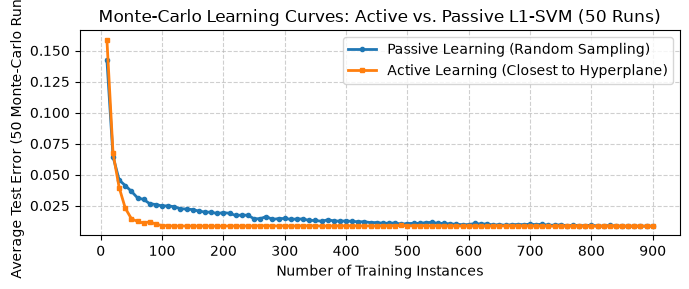

 Samples |  Passive Err |  Active Err |  Active - Passive
---------------------------------------------------------
      10 |       0.1425 |      0.1588 |           +0.0163
      30 |       0.0456 |      0.0396 |           -0.0061
      50 |       0.0365 |      0.0144 |           -0.0221
     100 |       0.0248 |      0.0090 |           -0.0158
     200 |       0.0194 |      0.0086 |           -0.0108
     400 |       0.0127 |      0.0087 |           -0.0040
     900 |       0.0085 |      0.0085 |           -0.0000

Overall mean error (10..900) - Passive: 0.0163 | Active: 0.0116


In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Load bundled Monte-Carlo simulation results
data = np.load("l1_svm_monte_carlo_results.npz")
train_sizes = data["train_sizes"]
all_passive_errors = data["all_passive_errors"]
mean_passive_errors = data["mean_passive_errors"]
all_active_errors = data["all_active_errors"]
mean_active_errors = data["mean_active_errors"]

# Plot both learning curves on the same figure
plt.figure(figsize=(7, 3))
plt.plot(
    train_sizes,
    mean_passive_errors,
    marker="o",
    markersize=3,
    linewidth=2,
    label="Passive Learning (Random Sampling)",
)
plt.plot(
    train_sizes,
    mean_active_errors,
    marker="s",
    markersize=3,
    linewidth=2,
    label="Active Learning (Closest to Hyperplane)",
)

plt.title("Monte-Carlo Learning Curves: Active vs. Passive L1-SVM (50 Runs)")
plt.xlabel("Number of Training Instances")
plt.ylabel("Average Test Error (50 Monte-Carlo Runs)")
plt.xticks(np.arange(0, 901, 100))
plt.legend(loc="best")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("learning_curves_active_vs_passive.png", dpi=300, bbox_inches="tight")
plt.show()

# Summary statistics across key training set sizes
sample_points = [10, 30, 50, 100, 200, 400, 900]
print(f"{'Samples':>8} | {'Passive Err':>12} | {'Active Err':>11} | {'Active - Passive':>17}")
print("-" * 57)
for n in sample_points:
    idx = np.where(train_sizes == n)[0][0]
    p_val = mean_passive_errors[idx]
    a_val = mean_active_errors[idx]
    print(f"{n:8d} | {p_val:12.4f} | {a_val:11.4f} | {a_val - p_val:+17.4f}")

print(f"\nOverall mean error (10..900) - Passive: {mean_passive_errors.mean():.4f} | Active: {mean_active_errors.mean():.4f}")

In the 50-run Monte-Carlo simulation for $\ell_1$-penalized linear SVMs, the overall average test error across 10 to 900 training samples is 0.0116 for active learning compared to 0.0163 for passive learning, demonstrating higher sample efficiency for active learning across most of the learning curve. At 10 samples, active learning starts with a slightly higher test error (0.1588) than passive learning (0.1425), but rapidly outperforms it from 30 samples onward—reaching 0.0144 at 50 samples (versus 0.0365 for passive learning) and 0.0090 at 100 samples (versus 0.0248 for passive learning). Both strategies converge to the same low test error of 0.0085 at 900 samples, while active learning incurs a higher computational cost due to per-step distance evaluations to the hyperplane.